# Modeling and Question Answering

In [1]:
import pandas as pd
import numpy as np

df_covid = pd.read_csv("covid_germany/covid_de_clean.csv")
df_demo = pd.read_csv("covid_germany/demographics_de_clean.csv")

## Split into training and testing set

In [2]:
from sklearn.model_selection import train_test_split

# keep rows with at least one case
df_cases = df_covid[df_covid["cases"] > 0]

# split the rows into training and testing sets (stratified on whether the row has any deaths)
train_df_covid, test_df_covid = train_test_split(
    df_cases, test_size=0.2, random_state=42, stratify=df_cases["deaths"] > 0)

print("Train rows:", len(train_df_covid))
print("Test rows:", len(test_df_covid))
print("Deaths in train:", train_df_covid["deaths"].sum())
print("Deaths in test:", test_df_covid["deaths"].sum())

Train rows: 552915
Test rows: 138229
Deaths in train: 61772
Deaths in test: 15601


The rows are split into training and testing sets before turning them into individuals, so the people from one row stay in the same set. The split is stratified on whether a row has any deaths, and the printed death counts and shares in the `Share who died in train` and `Share who died in test` lines of the later output show both sets have a similar death rate.

## Using Logistic Regression
Given that the datasets are aggregates across the country, not by individual basis, it is not reliable to preidict the outcome of an individual person surviving. However, a predicting outcomes by group-level based on demographic or geography is more feasible. 

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix

## Logistic Regression: Predicting Survival of an Individual

The data is aggregated where each row is a count of cases and deaths for a state, county, age group, gender and date. The rows were split into `train_df_covid` and `test_df_covid` above. Each part is then turned into individuals: every row becomes two records, one for people who died (`survived = 0`, weight = `deaths`) and one for people who survived (`survived = 1`, weight = `cases - deaths`). Records with a weight of 0 are dropped, and the weight is passed to the model as `sample_weight`. This is the simplest option because it avoids repeating every row once per person, which would make the data far larger.

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# turn aggregated rows into one died record and one survived record per row
def make_individuals(df):
    df_died = df[["state", "age_group", "gender", "month"]].copy()
    df_died["survived"] = 0
    df_died["weight"] = df["deaths"]

    df_survived = df[["state", "age_group", "gender", "month"]].copy()
    df_survived["survived"] = 1
    df_survived["weight"] = df["cases"] - df["deaths"]

    df_people = pd.concat([df_died, df_survived])
    return df_people[df_people["weight"] > 0]

# Unknown age_group / gender stay as their own category
df_model_train = make_individuals(train_df_covid)
df_model_test = make_individuals(test_df_covid)

print("Rows in df_model_train:", len(df_model_train))
print("Rows in df_model_test:", len(df_model_test))
print("People in train (sum of weights):", df_model_train["weight"].sum())
print("People in test (sum of weights):", df_model_test["weight"].sum())
print("Share who died in train:", round(df_model_train[df_model_train["survived"] == 0]["weight"].sum() / df_model_train["weight"].sum(), 4))
print("Share who died in test:", round(df_model_test[df_model_test["survived"] == 0]["weight"].sum() / df_model_test["weight"].sum(), 4))

Rows in df_model_train: 585683
Rows in df_model_test: 146412
People in train (sum of weights): 2327806
People in test (sum of weights): 582279
Share who died in train: 0.0265
Share who died in test: 0.0268


## Features and Target

The features are demographic (`age_group`, `gender`), geography (`state`) and time (`month`, as a category). `county` is left out because it has too many levels. All are one-hot encoded (on the training set, with the test set matched to the same columns) with `drop_first=True`.

In [5]:
features = ["age_group", "gender", "state", "month"]

X_train = pd.get_dummies(df_model_train[features], drop_first=True)
y_train = df_model_train["survived"]
w_train = df_model_train["weight"]

# use the same columns as the training set for the test set
X_test = pd.get_dummies(df_model_test[features], drop_first=True).reindex(columns=X_train.columns, fill_value=0)
y_test = df_model_test["survived"]
w_test = df_model_test["weight"]

print("Number of features:", X_train.shape[1])
print(X_train.columns.tolist())

Number of features: 38
['age_group_05-14', 'age_group_15-34', 'age_group_35-59', 'age_group_60-79', 'age_group_80-99', 'age_group_Unknown', 'gender_M', 'gender_Unknown', 'state_Bayern', 'state_Berlin', 'state_Brandenburg', 'state_Bremen', 'state_Hamburg', 'state_Hessen', 'state_Mecklenburg-Vorpommern', 'state_Niedersachsen', 'state_Nordrhein-Westfalen', 'state_Rheinland-Pfalz', 'state_Saarland', 'state_Sachsen', 'state_Sachsen-Anhalt', 'state_Schleswig-Holstein', 'state_Thueringen', 'month_2020-02', 'month_2020-03', 'month_2020-04', 'month_2020-05', 'month_2020-06', 'month_2020-07', 'month_2020-08', 'month_2020-09', 'month_2020-10', 'month_2020-11', 'month_2020-12', 'month_2021-01', 'month_2021-02', 'month_2021-03', 'month_2021-04']


## Fit the Model

`class_weight='balanced'` is used because far fewer people died than survived.

In [6]:
model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train, y_train, sample_weight=w_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

## Evaluation on the Test Set

Deaths are the class we want to find, so precision, recall and F1 are reported for `survived = 0` (`pos_label=0`). The metrics are weighted by the number of people in each record.

Accuracy: 0.8053
Precision (died): 0.1163
Recall (died): 0.9499
F1 (died): 0.2073

Confusion matrix (positive = died, each row adds up to 100%)
                              predicted died          predicted survived
actual died       True Positive (TP): 94.99%  False Negative (FN): 5.01%
actual survived  False Positive (FP): 19.87%  True Negative (TN): 80.13%

True Positive (TP): 94.99%
False Negative (FN): 5.01%
False Positive (FP): 19.87%
True Negative (TN): 80.13%

Baseline accuracy (always predict survived): 0.9732


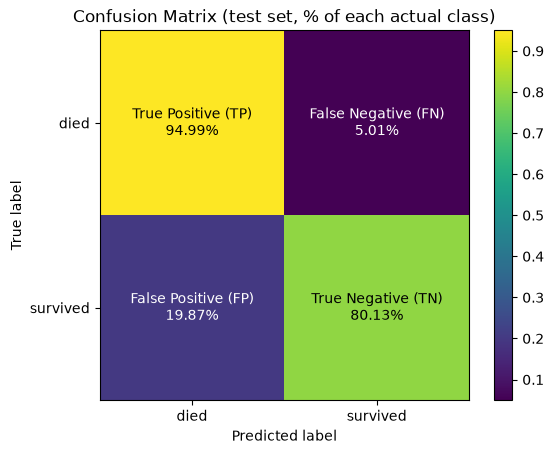

In [7]:
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred, sample_weight=w_test), 4))
print("Precision (died):", round(precision_score(y_test, y_pred, pos_label=0, sample_weight=w_test), 4))
print("Recall (died):", round(recall_score(y_test, y_pred, pos_label=0, sample_weight=w_test), 4))
print("F1 (died):", round(f1_score(y_test, y_pred, pos_label=0, sample_weight=w_test), 4))

# row percentages, positive class = died
cm = confusion_matrix(y_test, y_pred, labels=[0, 1], sample_weight=w_test, normalize="true") * 100
names = [["True Positive (TP)", "False Negative (FN)"],
         ["False Positive (FP)", "True Negative (TN)"]]

df_confusion = pd.DataFrame(
    [[f"{names[r][c]}: {cm[r][c]:.2f}%" for c in range(2)] for r in range(2)],
    index=["actual died", "actual survived"],
    columns=["predicted died", "predicted survived"])
print()
print("Confusion matrix (positive = died, each row adds up to 100%)")
print(df_confusion.to_string())
print()
print(f"True Positive (TP): {cm[0][0]:.2f}%")
print(f"False Negative (FN): {cm[0][1]:.2f}%")
print(f"False Positive (FP): {cm[1][0]:.2f}%")
print(f"True Negative (TN): {cm[1][1]:.2f}%")

baseline = (y_test * w_test).sum() / w_test.sum()
print()
print("Baseline accuracy (always predict survived):", round(baseline, 4))

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=["died", "survived"],
    sample_weight=w_test, normalize="true", include_values=False)
for r in range(2):
    for c in range(2):
        color = "white" if cm[r][c] < 50 else "black"
        disp.ax_.text(c, r, f"{names[r][c]}\n{cm[r][c]:.2f}%", ha="center", va="center", color=color)
plt.title("Confusion Matrix (test set, % of each actual class)")
plt.show()

With 'died' as the positive class, the model catches most deaths (Recall (died): 0.9499) but flags many survivors as dying, so Precision ('died') is only 0.1163 and F1 (died) is 0.2073. 
The True Positive (TP) rate is 94.99% and the False Negative (FN) rate is 5.01%, so few deaths are missed.
The False Positive (FP) rate is 19.87% and the True Negative (TN) rate is 80.13%, so many survivors are wrongly predicted as 'died'.
Accuracy (0.8053) is lower than the Baseline accuracy (0.9732) of always predicting survived, because `class_weight='balanced'` gives up accuracy for finding deaths.

## Cross-Validation (5-fold)


In [8]:
from sklearn.model_selection import KFold

# split the training rows into 5 folds, then turn each fold into individuals
kf = KFold(n_splits=5, shuffle=True, random_state=42)
train_rows = train_df_covid.reset_index(drop=True)

accs, precs, recs, f1s = [], [], [], []

for fold, (tr_idx, va_idx) in enumerate(kf.split(train_rows), start=1):
    df_fold_train = make_individuals(train_rows.iloc[tr_idx])
    df_fold_val = make_individuals(train_rows.iloc[va_idx])

    X_tr = pd.get_dummies(df_fold_train[features], drop_first=True)
    y_tr = df_fold_train["survived"]
    w_tr = df_fold_train["weight"]

    X_va = pd.get_dummies(df_fold_val[features], drop_first=True).reindex(columns=X_tr.columns, fill_value=0)
    y_va = df_fold_val["survived"]
    w_va = df_fold_val["weight"]

    fold_model = LogisticRegression(class_weight="balanced", max_iter=1000)
    fold_model.fit(X_tr, y_tr, sample_weight=w_tr)
    y_hat = fold_model.predict(X_va)

    acc = accuracy_score(y_va, y_hat, sample_weight=w_va)
    prec = precision_score(y_va, y_hat, pos_label=0, sample_weight=w_va)
    rec = recall_score(y_va, y_hat, pos_label=0, sample_weight=w_va)
    f1 = f1_score(y_va, y_hat, pos_label=0, sample_weight=w_va)

    accs.append(acc)
    precs.append(prec)
    recs.append(rec)
    f1s.append(f1)

    print(f"Fold {fold}: Accuracy: {acc:.4f}  Precision (died): {prec:.4f}  Recall (died): {rec:.4f}  F1 (died): {f1:.4f}")

print()
print(f"Accuracy: mean: {np.mean(accs):.4f} +/- {np.std(accs, ddof=1):.4f}")
print(f"Precision (died): mean: {np.mean(precs):.4f} +/- {np.std(precs, ddof=1):.4f}")
print(f"Recall (died): mean: {np.mean(recs):.4f} +/- {np.std(recs, ddof=1):.4f}")
print(f"F1 (died): mean: {np.mean(f1s):.4f} +/- {np.std(f1s, ddof=1):.4f}")


Fold 1: Accuracy: 0.8112  Precision (died): 0.1166  Recall (died): 0.9452  F1 (died): 0.2075


Fold 2: Accuracy: 0.8038  Precision (died): 0.1167  Recall (died): 0.9521  F1 (died): 0.2079


Fold 3: Accuracy: 0.8085  Precision (died): 0.1163  Recall (died): 0.9469  F1 (died): 0.2071


Fold 4: Accuracy: 0.8038  Precision (died): 0.1150  Recall (died): 0.9521  F1 (died): 0.2051


Fold 5: Accuracy: 0.8070  Precision (died): 0.1159  Recall (died): 0.9485  F1 (died): 0.2066

Accuracy: mean: 0.8069 +/- 0.0032
Precision (died): mean: 0.1161 +/- 0.0007
Recall (died): mean: 0.9490 +/- 0.0031
F1 (died): mean: 0.2068 +/- 0.0011


Without cross-validation, the single train/test split gives an accuracy of 0.8053, a precision of 0.1163, a recall of 0.9499, and an F1 of 0.2073. With 5-fold cross-validation, the means are 0.8069 +/- 0.0032, 0.1161 +/- 0.0007, 0.9490 +/- 0.0031, and 0.2068 +/- 0.0011. These means are nearly identical to the single-split results, and the standard deviations are small, so that one split was not due to variance. Cross-validation does not improve the model itself; it only confirms the estimate.


## Coefficients

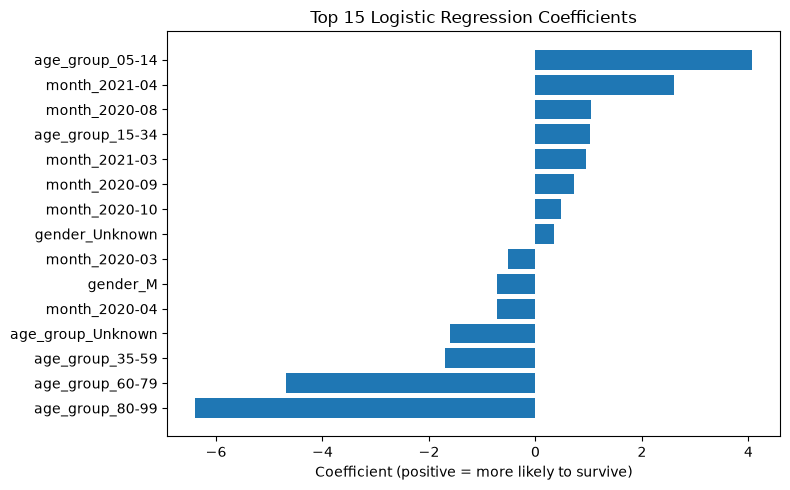

In [9]:
df_coef = pd.DataFrame({"feature": X_train.columns, "coefficient": model.coef_[0]})
df_coef = df_coef.reindex(df_coef["coefficient"].abs().sort_values(ascending=False).index)
df_top = df_coef.head(15).sort_values("coefficient")

plt.figure(figsize=(8, 5))
plt.barh(df_top["feature"], df_top["coefficient"])
plt.xlabel("Coefficient (positive = more likely to survive)")
plt.title("Top 15 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

## Note on the Features

These features are not optimal for predicting survival: they are very broad (state, age band, gender, month), contain no personal clinical information, and the classes are heavily imbalanced.